# imports, rutas y constantes

In [21]:
import sys
sys.path.append("/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/src")

import matplotlib.pyplot as plt
import pandas as pd
from run_nextclade import descargar_dataset_sars_cov2, alinear_año

In [ ]:
RAW_DIR = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/raw"
REFERENCE_FASTA = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/raw/reference/wuhan_ref.fasta"
GISAID_MEX_FASTA = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/raw/gisaid_hcov-19_2026_10_02_20.fasta"
DATASET_DIR = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/sars-cov-2"
RESULTS_DIR = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/results/nextclade"

print("Referencia Wuhan:", REFERENCE_FASTA)
print("Genoma mexicano temprano:", GISAID_MEX_FASTA)
print("Carpeta de resultados:", RESULTS_DIR)


Referencia Wuhan: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/raw/reference/wuhan_ref.fasta
Genoma mexicano temprano: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/raw/gisaid_hcov-19_2026_10_02_20.fasta
Carpeta de resultados: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/results/nextclade


In [ ]:
descargar_dataset_sars_cov2(output_dir=DATASET_DIR)

[DOWNLOAD] Descargando dataset de SARS-CoV-2...
[OK] Dataset descargado en /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/sars-cov-2


True

# preparar el FASTA de 2020 con el genoma mexicano incluido

In [20]:
fasta_2020 = f"{RAW_DIR}/ncbi_2020.fasta"
fasta_2020_con_mex = f"{RESULTS_DIR}/input_2020_con_mexicano.fasta"

with open(fasta_2020, "r") as f:
    secuencias_2020 = f.read()

with open(GISAID_MEX_FASTA, "r") as f:
    secuencias_mexicanas = f.read()

with open(fasta_2020_con_mex, "w") as f:
    f.write(secuencias_2020)
    f.write("\n")
    f.write(secuencias_mexicanas)

print("Archivo generado:", fasta_2020_con_mex)


Archivo generado: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/results/nextclade/input_2020_con_mexicano.fasta


# alinear todos los años (2020-2024)

In [8]:
years = [2020, 2021, 2022, 2023, 2024]
resultados = {}

In [ ]:
for year in years:

    if year == 2020:
        input_fasta = f"{RESULTS_DIR}/input_2020_con_mexicano.fasta"
    else:
        input_fasta = f"{RAW_DIR}/ncbi_{year}.fasta"

    output_tsv = f"{RESULTS_DIR}/nextclade_{year}.tsv"
    output_fasta = f"{RESULTS_DIR}/alineamiento_{year}.fasta"

    alinear_año(
        año=year,
        input_fasta=input_fasta,
        output_tsv=output_tsv,
        output_fasta=output_fasta,
        dataset_dir=DATASET_DIR
    )

[ALIGN] Año 2020: input_2020_con_mexicano.fasta
[OK] Año 2020 completado -> nextclade_2020.tsv
[ALIGN] Año 2021: ncbi_2021.fasta
[OK] Año 2021 completado -> nextclade_2021.tsv
[ALIGN] Año 2022: ncbi_2022.fasta
[OK] Año 2022 completado -> nextclade_2022.tsv
[ALIGN] Año 2023: ncbi_2023.fasta
[OK] Año 2023 completado -> nextclade_2023.tsv
[ALIGN] Año 2024: ncbi_2024.fasta
[OK] Año 2024 completado -> nextclade_2024.tsv


# Verificación de tsv 

In [9]:
for year in years:
    tsv_path = f"{RESULTS_DIR}/nextclade_{year}.tsv"
    df = pd.read_csv(tsv_path, sep="\t")
    print(f"{year}: {len(df)} secuencias | columnas: {list(df.columns[:4])}...")


2020: 81 secuencias | columnas: ['index', 'seqName', 'clade', 'clade_display']...
2021: 80 secuencias | columnas: ['index', 'seqName', 'clade', 'clade_display']...
2022: 80 secuencias | columnas: ['index', 'seqName', 'clade', 'clade_display']...
2023: 80 secuencias | columnas: ['index', 'seqName', 'clade', 'clade_display']...
2024: 80 secuencias | columnas: ['index', 'seqName', 'clade', 'clade_display']...


# Gráficas

In [ ]:
from pathlib import Path

RESULTS_DIR = Path("../results/nextclade")
años = [2020, 2021, 2022, 2023, 2024]

# Cargar y combinar
dfs = []
for año in años:
    df = pd.read_csv(RESULTS_DIR / f"nextclade_{año}.tsv", sep="\t")
    df["año"] = año
    dfs.append(df)
df_total = pd.concat(dfs, ignore_index=True)

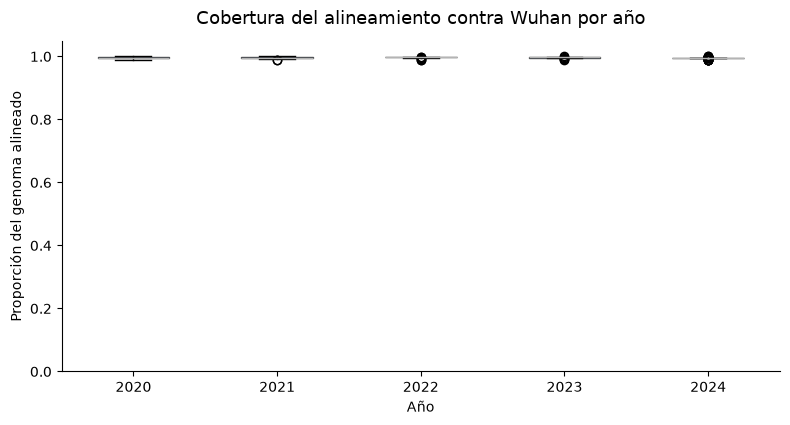

In [ ]:
# Calcular cobertura como proporción de la longitud de la referencia

LONGITUD_REF = 29903 # (NC_045512.2 mide 29,903 bp)

df_total["cobertura"] = (df_total["alignmentEnd"] - df_total["alignmentStart"] + 1) / LONGITUD_REF

fig, ax = plt.subplots(figsize=(8, 4.5))
df_total.boxplot(column="cobertura", by="año", ax=ax, grid=False, patch_artist=True,
                 boxprops=dict(facecolor="#4C72B0", alpha=0.7))

ax.set_title("Cobertura del alineamiento contra Wuhan por año", fontsize=13, pad=12)
ax.set_xlabel("Año")
ax.set_ylabel("Proporción del genoma alineado")
ax.set_ylim(0, 1.05)
plt.suptitle("")  # quitar el título automático de pandas
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

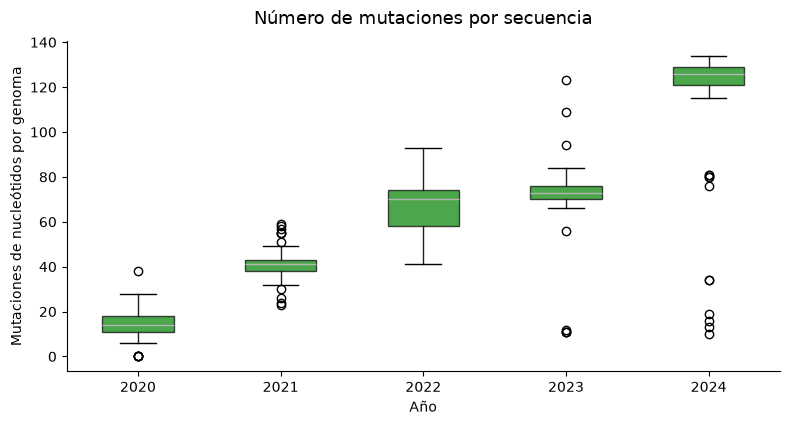

In [25]:
# Contar mutaciones por secuencia (separadas por comas)
df_total["n_mutaciones"] = df_total["substitutions"].fillna("").apply(
    lambda x: len([m for m in x.split(",") if m.strip()])
)

fig, ax = plt.subplots(figsize=(8, 4.5))
df_total.boxplot(column="n_mutaciones", by="año", ax=ax, grid=False, patch_artist=True,
                 boxprops=dict(facecolor="green", alpha=0.7))

ax.set_title("Número de mutaciones por secuencia", fontsize=13, pad=12)
ax.set_xlabel("Año")
ax.set_ylabel("Mutaciones de nucleótidos por genoma")
plt.suptitle("")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

plt.show()